Content I'm Using:
    For my project, I want to first compare two books by Herman Melville: "Moby Dick; Or, The Whale" and "The Confidence-Man: His Masquerade". 
    For the comparsion between two authors, I want to use "Dracula" by Bram Stoker and "Alice's Adventures in Wonderland" by Lewis Carroll.

Methods:
    I am going to compare the word frequencies between the two books by Herman Melville, and also between the two books written by different authors. 
    I will do this by scanning through the texts and keeping word counts using a dictionary.

Goal:
    Since these books are all works of classic literature, I want to see which words were popularly used during the time when these books 
    were written. I want to compare these results to statistics of word frequencies in today's works of literature. 
    Overall, I want to look at how dialect has changed over time.

Presentation of Data:
    I will present these results from the books using graphs and charts. Also, I plan to compare these results to statistics of the most 
    commonly used words in today's literature, taken from an online source.

# Mini Project 1: Annie Fink

In [1]:
import requests, re, nltk
from bs4 import BeautifulSoup
from nltk import clean_html
from collections import Counter
import operator

# we may not care about the usage of stop words
stop_words = nltk.corpus.stopwords.words('english') + [
 'ut', '\'re','.', ',', '--', '\'s', '?', ')', '(', ':', '\'',
 '\"', '-', '}', '{', '&', '|', u'\u2014' ]

# We most likely would like to remove html markup
def cleanHtml (html):
    from bs4 import BeautifulSoup
    soup = BeautifulSoup(html, 'html.parser')
    return soup .get_text()

# We also want to remove special characters, quotes, etc. from each word
def cleanWord (w):
    # r in r'[.,"\']' tells to treat \ as a regular character 
    # but we need to escape ' with \'
    # any character between the brackets [] is to be removed 
    wn = re.sub('[,"\.\'&\|:@>*;/=]', "", w)
    # get rid of numbers
    return re.sub('^[0-9\.]*$', "", wn)
       
# define a function to get text/clean/calculate frequency
def get_wf (URL):
    # first get the web page
    r = requests .get(URL)
    
    # Now clean
    # remove html markup
    t = cleanHtml (r .text) .lower()
     # split string into an array of words using any sequence of spaces "\s+" 
    wds = re .split('\s+',t)
    
    # remove periods, commas, etc stuck to the edges of words
    for i in range(len(wds)):
        wds [i] = cleanWord (wds [i])
    
    # If satisfied with results, lets go to the next step: calculate frequencies
    # We can write a loop to create a dictionary, but 
    # there is a special function for everything in python
    # in particular for counting frequencies (like function table() in R)
    wf = Counter (wds)
    
    # Remove stop words from the dictionary wf
    for k in stop_words:
        wf. pop(k, None)
        
    #how many regular words in the document?
    tw = 0
    for w in wf:
       tw += wf[w] 
        
    
    # Get ordered list
    wfs = sorted (wf .items(), key = operator.itemgetter(1), reverse=True)
    ml = min(len(wfs),15)

    #Reverse the list because barh plots items from the bottom
    return (wfs [ 0:ml ] [::-1], tw)
        
# Now populate two lists  

# Same authors
(wf_MD, tw_MD) = get_wf('https://www.gutenberg.org/cache/epub/2701/pg2701.txt') # Moby Dick; or The Whale - Herman Melville
(wf_CM, tw_CM) = get_wf('https://www.gutenberg.org/cache/epub/21816/pg21816.txt') # The Confidence-Man: His Masquerade -  Herman Melville

# Different authors
(wf_RJ, tw_RJ) = get_wf('https://www.gutenberg.org/cache/epub/1513/pg1513.txt') # Romeo and Juliet - William Shakespeare
(wf_AW, tw_AW) = get_wf('https://www.gutenberg.org/cache/epub/11/pg11.txt') # Alice's Adventures in Wonderland - Lewis Carroll

In [2]:
#Plot the results: are there striking differences in language?
import numpy as np
import pylab
import matplotlib.pyplot as plt

%matplotlib inline
def plotTwoLists (wf_1, wf_2, title):
    f = plt.figure (figsize=(10, 6))
    # this is painfully tedious....
    f .suptitle (title, fontsize=20)
    ax = f.add_subplot(111)
    ax .spines ['top'] .set_color ('none')
    ax .spines ['bottom'] .set_color ('none')
    ax .spines ['left'] .set_color ('none')
    ax .spines ['right'] .set_color ('none')
    ax .tick_params (labelcolor='w', top='off', bottom='off', left='off', right='off', labelsize=20)

    # Create two subplots, this is the first one
    ax1 = f .add_subplot (121)
    plt .subplots_adjust (wspace=.5)

    pos = np .arange (len(wf_1)) 
    ax1 .tick_params (axis='both', which='major', labelsize=14)
    pylab .yticks (pos, [ x [0] for x in wf_1 ])
    ax1 .barh (range(len(wf_1)), [ x [1] for x in wf_1 ], align='center')

    ax2 = f .add_subplot (122)
    ax2 .tick_params (axis='both', which='major', labelsize=14)
    pos = np .arange (len(wf_2)) 
    pylab .yticks (pos, [ x [0] for x in wf_2 ])
    ax2 .barh (range (len(wf_2)), [ x [1] for x in wf_2 ], align='center')

# PART 1: Comparing Word Frequencies Between Two Works by the Same Author 
Moby Dick; or The Whale and The Confidence-Man: His Masquerade, both by Herman Melville

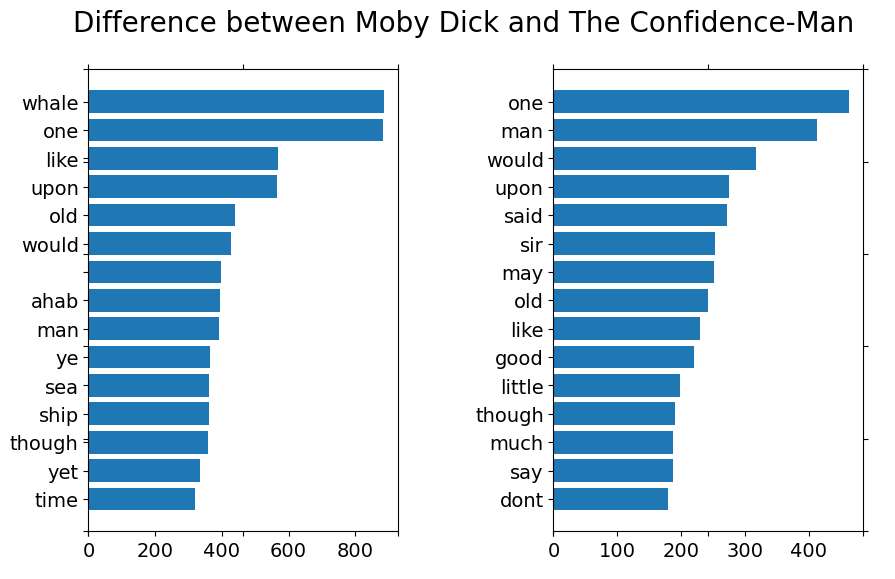

In [3]:

plotTwoLists (wf_MD, wf_CM, 'Difference between Moby Dick and The Confidence-Man')

These two texts have very similar lists. Both lists include 7 of the same words, including "one", "like", "would", "upon", "old", "man", and "though". This indicates that authors are more likely to use similar wordings when writing different pieces of literature. It makes sense that words like "whale" and "sea" are used a lot in Moby Dick and not in The Confidence-Man, since the story is about a fisherman in the sea. Also, the overall word counts for the frequencies in Moby Dick are consistently higher than in The Confidence-Man, which suggests that Moby Dick may be a longer book, or The Confidence-Man has a more even spread between word frequencies throughout the book.

# PART 2: Comparing Word Frequencies Between Works by the Different Authors 
Romeo and Juliet by William Shakespeare and Alice's Adventures in Wonderland by Lewis Carroll

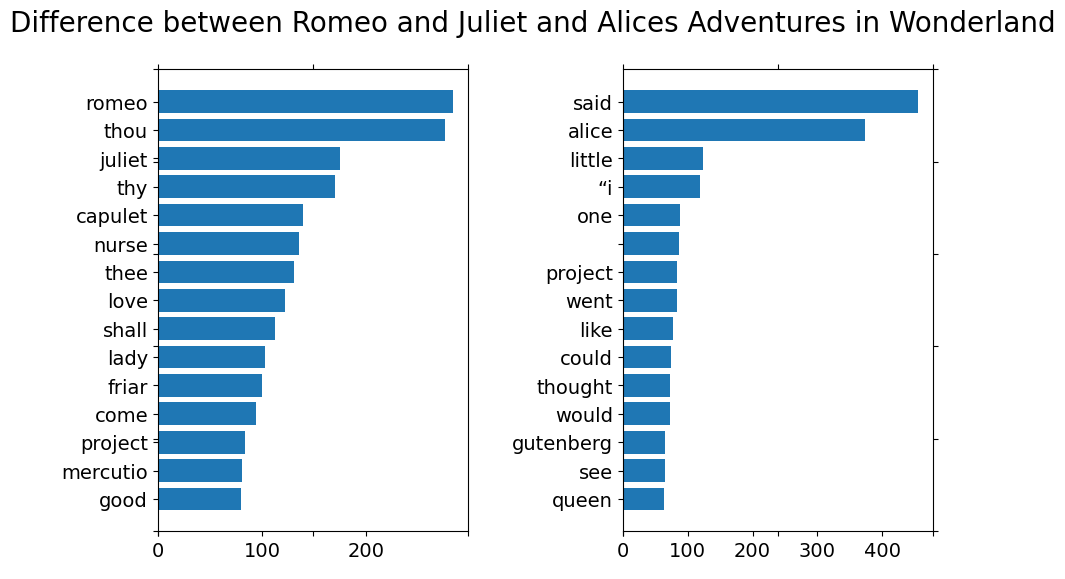

In [4]:
plotTwoLists (wf_RJ, wf_AW, 'Difference between Romeo and Juliet and Alices Adventures in Wonderland')


These two authors both use character names frequently throughout their works, since Shakespeare's Romeo and Julet includes 
"romeo", "juliet", "mercucio", etc., and Lewis Carroll's Alices Adventures in Wonderland includes "alice" and "queen". Shakespeare's text utlizes
old english dialect such as "thou", "thy", and "shall", which are not present in Carroll's work. This can indicate the time period that these books 
were written in, since dialect changes over time. Also, both works have two words each that are used way more frequently than other words in the text.
However, there is a much larger difference bewteen the overall frequencies of these two words compared to other words in the text. "Said" and "Alice" 
seem to be used quite a lot more than other frequent words in the text, while the top two for Shakespeare's, "romeo" and thou", aren't as far ahead 
compared to other words in the text.


# PART 3: Are there some words preferred by one author but used less frequently by another author?


Herman Melville has similar words between his two works that are used very frequently, such as "one", "upon", and "old", that 
are not used frequently in the other works by William Shakespeare and Lewis Carroll. 

Also, Shakespeare frequently uses words from old english dialect, such as "thou", "thy", and "shall", which are not present in the other works. 

Lewis Carrol's work indicates that there is a lot of dialogue in the book, since "said" and "thought" are used very often in the text. These words 
aren't in the top most frequent words for the other authors.


# Extra Credit

In [10]:
word = "would"

#moby dick
N = tw_MD
k = dict(wf_MD).get(word, 0)
p = k / N
print(f"Moby Dick by Herman Melville | p = {p}  | {p:.2%}")

# confidence-man
N = tw_CM
k = dict(wf_CM).get(word, 0)
p = k / N
print(f"The Confidence Man by Herman Melville | p = {p}  | {p:.2%}")

# romeo and juliet
N = tw_RJ
k = dict(wf_RJ).get(word, 0)
p = k / N
print(f"Romeo and Juliet by William Shakespeare  | p = {p}  | {p:.2%}")

# alices adventures in wonderland
N = tw_AW
k = dict(wf_AW).get(word, 0)
p = k / N
print(f"Alices Adventures in Wonderland by lewis Carroll | p = {p}  | {p:.2%}")

Moby Dick by Herman Melville | p = 0.003786501609484876  | 0.38%
The Confidence Man by Herman Melville | p = 0.006571877324956601  | 0.66%
Romeo and Juliet by William Shakespeare  | p = 0.0  | 0.00%
Alices Adventures in Wonderland by lewis Carroll | p = 0.004560425639726374  | 0.46%


The binomial distributions bewteen the two works by Herman Melville differ, with The Condfidence-Man having a higher p value of 0.66% than Moby Dick, which has a p value of 0.38%. These numbers are greater than the binomial distribution for "would" in Romeo and Juliet, which has a 0.00% p value. The work by Lewis Carroll falls in bewteen the numbers from Herman Melville's literature, with a p value of 0.46%.

# Overview / Presentation